# Лабораторная работа № 4
## Прогнозирование телеметрических параметров космического аппарата с помощью рекуррентной нейронной сети LSTM

**Датасет:** XJTU-SPS, поднабор `F or R`, файл `XJTU-SPS for F or R_94cycles.csv`.

### Цель работы
Изучить прогнозирование временных рядов на основе исторических телеметрических данных. Подготовить оконные выборки, обучить рекуррентную нейронную сеть LSTM и оценить качество прогноза.

### Задачи
1. Загрузить и изучить CSV-файл.
2. Проверить структуру, типы данных и пропуски.
3. Выбрать числовые телеметрические параметры для прогнозирования.
4. Построить графики исходных временных рядов.
5. Подготовить данные: очистка, масштабирование и разделение по времени.
6. Сформировать оконные выборки для обучения с учителем.
7. Создать и обучить модель LSTM.
8. Получить прогноз на тестовом участке.
9. Оценить качество с помощью MAE и RMSE.
10. Построить графики сравнения фактических и прогнозируемых значений.


**Прогноз в этой работе:** по предыдущим `WINDOW_SIZE` наблюдениям модель предсказывает значения выбранных параметров на следующем временном шаге (частота исходного поднабора по описанию датасета — 1 Гц).

## 1. Подготовка среды и импорт библиотек

В этой работе используются:
- `pandas` и `numpy` — чтение и обработка таблиц;
- `matplotlib` — визуализация;
- `scikit-learn` — масштабирование и метрики;
- `tensorflow / keras` — создание и обучение LSTM.

Запустите ячейку. Если появляется `ModuleNotFoundError`, установите отсутствующую библиотеку в том Python-окружении, которое выбрано как ядро Jupyter.

In [1]:
import os
import sys
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings("ignore")
np.random.seed(42)
tf.random.set_seed(42)

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("TensorFlow:", tf.__version__)
print("Библиотеки успешно подключены.")

Pandas: 3.1.1
NumPy: 2.5.5
Scikit-learn: 1.9.1
TensorFlow: 2.22.0-rc1
Библиотеки успешно подключены.


## 2. Поиск и загрузка исходного CSV-файла


In [2]:
CSV_PATH = os.path.join("data", "XJTU-SPS%20for%20F%20or%20R_94cycles.csv")

if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(
        f"Файл не найден: {CSV_PATH}\n"
        f"Текущая рабочая папка: {os.getcwd()}\n"
        "Проверьте, что CSV находится в папке data внутри lab04."
    )

print("Файл найден")
print("Размер файла, МБ:", round(os.path.getsize(CSV_PATH) / (1024 ** 2), 2))

Файл найден
Размер файла, МБ: 100.95


### 2.1. Чтение CSV

Сначала пробуем автоматически определить разделитель. Для файлов с кириллицей предусмотрена резервная кодировка.

In [3]:
def read_csv_robust(path):
    encodings = ["utf-8-sig", "utf-8", "cp1251"]
    last_error = None

    for encoding in encodings:
        try:
            data = pd.read_csv(
                path,
                sep=None,
                engine="python",
                encoding=encoding
            )
            if data.shape[1] > 1:
                print(f"Файл прочитан. Кодировка: {encoding}")
                return data
        except Exception as error:
            last_error = error

    raise RuntimeError(f"Не удалось прочитать CSV. Последняя ошибка: {last_error}")

df_raw = read_csv_robust(CSV_PATH)

print("Размер таблицы (строки, столбцы):", df_raw.shape)
display(df_raw.head())

Файл прочитан. Кодировка: utf-8-sig
Размер таблицы (строки, столбцы): (523581, 34)


,Time,U_SA,I_SA,P_SA,U_Load_output,I_Load_output,P_Load_output,U_BCR,I_BCR,P_BCR,...,T_Load1,P_Load1,U_Load2,I_Load2,T_Load2,P_Load2,U_Load3,I_Load3,T_Load3,P_Load3
0,2024-10-22 18:59:21,0.2413,0.0000,0.0,0.000,0.0,0.0,16.402,0.000,0.000,...,27.8,0.0,5.295,0.0,28.5,0.0,5.408,0.000,29.3,0.000
1,2024-10-22 18:59:22,30.7840,0.0035,0.1,0.000,0.0,0.0,16.401,0.000,0.000,...,27.8,0.0,5.294,0.0,28.5,0.0,5.408,0.000,29.3,0.000
2,2024-10-22 18:59:23,21.6180,2.6658,57.6,0.009,0.0,0.0,16.403,0.000,0.000,...,27.8,0.0,5.294,0.0,28.5,0.0,5.408,0.003,29.3,0.016
3,2024-10-22 18:59:24,24.2000,2.4747,59.9,0.001,0.0,0.0,16.402,0.011,0.180,...,27.8,0.0,5.294,0.0,28.5,0.0,5.408,0.000,29.3,0.000
4,2024-10-22 18:59:25,24.2670,2.4696,59.9,0.001,0.0,0.0,16.683,2.997,49.999,...,27.8,0.0,5.294,0.0,28.3,0.0,5.408,0.000,29.3,0.000


## 3. Первичный анализ данных


### 3.1. Подготовка числовых столбцов

LSTM принимает числовые последовательности. Текстовые столбцы не передаются в модель. Столбцы, которые полностью состоят из пропусков, также исключаются.

Числовые значения, сохранённые в CSV как текст, пробуем преобразовать в числа. Исходный `df_raw` оставляем без изменений.

In [5]:
df = df_raw.copy()

# Убираем лишние пробелы в названиях столбцов
df.columns = [str(col).strip() for col in df.columns]

# Пробуем преобразовать текстовые столбцы в числовые
for col in df.columns:
    if not pd.api.types.is_numeric_dtype(df[col]):
        converted = pd.to_numeric(
            df[col].astype(str).str.replace(",", ".", regex=False),
            errors="coerce"
        )
        # Преобразуем столбец, если числовыми стали хотя бы 80% непустых значений
        non_empty = df[col].notna().sum()
        if non_empty > 0 and converted.notna().sum() / non_empty >= 0.8:
            df[col] = converted

numeric_columns = df.select_dtypes(include=[np.number]).columns.tolist()

print("Числовые столбцы:")
print(numeric_columns)
print("\nКоличество числовых столбцов:", len(numeric_columns))

if not numeric_columns:
    raise ValueError(
        "В файле не обнаружены числовые столбцы. "
        "Проверьте разделитель, строку заголовка и формат CSV."
    )

Числовые столбцы:
['U_SA', 'I_SA', 'P_SA', 'U_Load_output', 'I_Load_output', 'P_Load_output', 'U_BCR', 'I_BCR', 'P_BCR', 'U_BAT2', 'I_BAT2', 'T_BAT2', 'U_BAT3', 'I_BAT3', 'T_BAT3', 'U_BAT4', 'I_BAT4', 'T_BAT4', 'U_Bus', 'I_Bus', 'P_Bus', 'U_Load1', 'I_Load1', 'T_Load1', 'P_Load1', 'U_Load2', 'I_Load2', 'T_Load2', 'P_Load2', 'U_Load3', 'I_Load3', 'T_Load3', 'P_Load3']

Количество числовых столбцов: 33


## 4. Выбор параметров для прогнозирования

В идеале для задания выбирают температуру, напряжение и ток. Но в конкретном файле названия могут быть техническими или обозначать каналы датчиков.

Ниже действует следующий алгоритм:
1. Ищутся столбцы, в названии которых есть слова/сокращения температуры, напряжения или тока.
2. Если такие названия не найдены, выбираются первые три числовых столбца, кроме очевидных идентификаторов и временных индексов.
3. После вывода списка можно вручную задать `TARGET_COLUMNS`.

**Проверьте выведенный список.** Если вы знаете, какие именно каналы являются температурой, напряжением и током, укажите их точные имена в `TARGET_COLUMNS`.

In [7]:
# ВАРИАНТ 1: оставьте None для автоматического выбора.
# ВАРИАНТ 2: укажите вручную точные имена, например:
# TARGET_COLUMNS = ["temperature", "voltage", "current"]

TARGET_COLUMNS = None

def choose_target_columns(columns):
    groups = {
        "temperature": ["temperature", "temp", "температур", "теплов"],
        "voltage": ["voltage", "volt", "напряж", "вольт"],
        "current": ["current", "curr", "ток", "амп"]
    }

    selected = []
    lower_names = {col: str(col).lower() for col in columns}

    for group, keywords in groups.items():
        matches = [
            col for col in columns
            if any(word in lower_names[col] for word in keywords)
        ]
        if matches:
            selected.append(matches[0])

    if selected:
        return list(dict.fromkeys(selected))

    excluded_words = ["id", "index", "time", "timestamp", "date", "cycle", "номер"]
    candidates = [
        col for col in columns
        if not any(word in str(col).lower() for word in excluded_words)
    ]
    return candidates[:3] if candidates else list(columns[:3])

if TARGET_COLUMNS is None:
    TARGET_COLUMNS = choose_target_columns(numeric_columns)

missing_targets = [col for col in TARGET_COLUMNS if col not in df.columns]
if missing_targets:
    raise ValueError(f"Указанные столбцы отсутствуют в CSV: {missing_targets}")

non_numeric_targets = [
    col for col in TARGET_COLUMNS
    if not pd.api.types.is_numeric_dtype(df[col])
]
if non_numeric_targets:
    raise ValueError(f"Эти столбцы не являются числовыми: {non_numeric_targets}")

print("Выбранные параметры для прогнозирования:")
for col in TARGET_COLUMNS:
    print("-", col)


Выбранные параметры для прогнозирования:
- U_SA
- I_SA
- P_SA


## 5. Визуальный анализ временных рядов

Построим графики выбранных параметров в исходном масштабе. По графикам можно увидеть диапазон значений, резкие скачки, тренд и возможные аномалии.

По оси X используется номер наблюдения. Если в CSV есть отдельный корректный столбец времени, его можно дополнительно использовать вместо номера наблюдения.

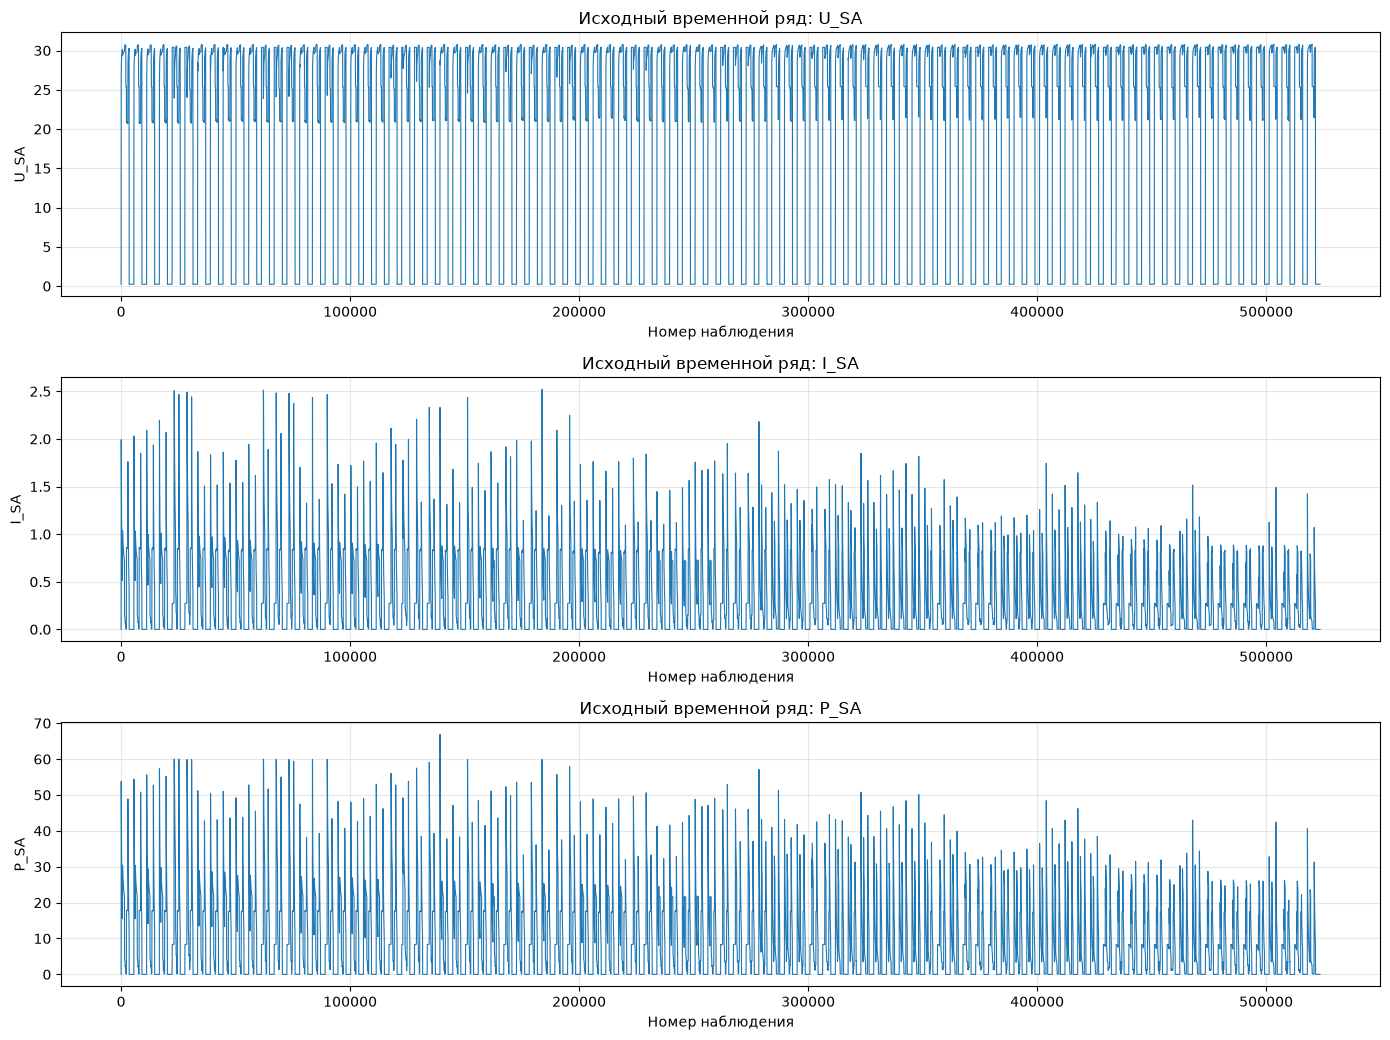

In [8]:
MAX_PLOT_POINTS = 10000

plot_step = max(1, len(df) // MAX_PLOT_POINTS)
plot_data = df[TARGET_COLUMNS].iloc[::plot_step].copy()

fig, axes = plt.subplots(
    len(TARGET_COLUMNS), 1,
    figsize=(14, 3.5 * len(TARGET_COLUMNS)),
    squeeze=False
)

for i, col in enumerate(TARGET_COLUMNS):
    axes[i, 0].plot(plot_data.index, plot_data[col], linewidth=0.8)
    axes[i, 0].set_title(f"Исходный временной ряд: {col}")
    axes[i, 0].set_xlabel("Номер наблюдения")
    axes[i, 0].set_ylabel(str(col))
    axes[i, 0].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 5.1. Проверка распределения и пропусков выбранных параметров

Гистограммы помогают понять распределение значений, а таблица ниже показывает пропуски и основные статистики.

,count,mean,std,min,25%,50%,75%,max
U_SA,523581.0,17.993861,13.795562,0.1982,0.2424,25.4020,30.2280,30.7870
I_SA,523581.0,0.324690,0.417005,0.0000,0.0000,0.1172,0.6649,2.6723
P_SA,523581.0,9.034526,11.473060,0.0000,0.0000,3.6000,17.5000,66.9000


,Количество пропусков
U_SA,0
I_SA,0
P_SA,0


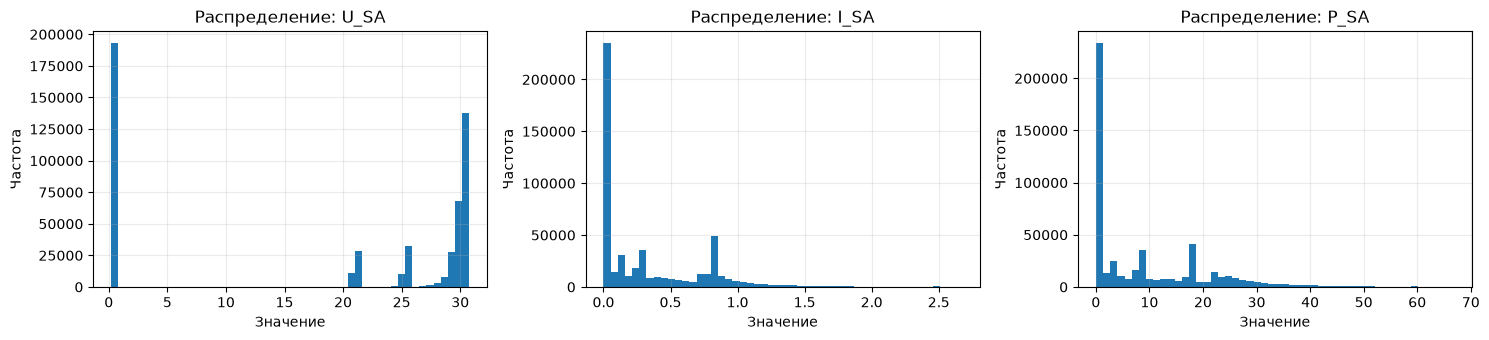

In [9]:
display(df[TARGET_COLUMNS].describe().T)
display(df[TARGET_COLUMNS].isna().sum().to_frame("Количество пропусков"))

fig, axes = plt.subplots(
    1, len(TARGET_COLUMNS),
    figsize=(5 * len(TARGET_COLUMNS), 3.5),
    squeeze=False
)

for i, col in enumerate(TARGET_COLUMNS):
    values = pd.to_numeric(df[col], errors="coerce").dropna()
    axes[0, i].hist(values, bins=50)
    axes[0, i].set_title(f"Распределение: {col}")
    axes[0, i].set_xlabel("Значение")
    axes[0, i].set_ylabel("Частота")
    axes[0, i].grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

## 6. Очистка и подготовка данных

Для обучения используем только выбранные параметры. Пропущенные значения интерполируем по порядку наблюдений, затем заполняем возможные пропуски по краям ближайшими значениями.

Далее ограничиваем максимальный объём строк для обучения. Это сделано для того, чтобы ноутбук мог работать на обычном компьютере. Если данных меньше лимита, используются все строки. При необходимости лимит можно увеличить.

In [10]:
# Максимальное число наблюдений для обучения.
# Увеличивайте значение, если хватает оперативной памяти и времени.
MAX_ROWS = 120_000

data = df[TARGET_COLUMNS].copy()

# Приводим к числовому виду и заменяем бесконечности на пропуски
for col in TARGET_COLUMNS:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data = data.replace([np.inf, -np.inf], np.nan)

# Удаляем строки, в которых все выбранные параметры отсутствуют
data = data.dropna(how="all")

# Интерполяция по времени наблюдений
data = data.interpolate(method="linear", limit_direction="both")
data = data.ffill().bfill()

# Удаляем константные/непригодные столбцы
valid_columns = [
    col for col in data.columns
    if data[col].nunique(dropna=True) > 1 and data[col].notna().all()
]
data = data[valid_columns]
TARGET_COLUMNS = valid_columns

if data.shape[1] == 0:
    raise ValueError("После очистки не осталось изменяющихся числовых параметров.")

# Ограничиваем размер данных, сохраняя временной порядок
if len(data) > MAX_ROWS:
    data = data.iloc[:MAX_ROWS].copy()

data = data.astype("float32")

# Сохраняем обработанный и сокращённый датасет.
# Исходный CSV не изменяется.
os.makedirs("data", exist_ok=True)
PROCESSED_DATA_PATH = os.path.join("data", "processed_dataset.csv")
data.to_csv(PROCESSED_DATA_PATH, index=False, encoding="utf-8-sig")

print("Обработанный датасет сохранён:", PROCESSED_DATA_PATH)
print("Размер данных после очистки:", data.shape)
print("Параметры модели:", data.columns.tolist())
print("Осталось пропусков:", int(data.isna().sum().sum()))
display(data.head())

Обработанный датасет сохранён: data\processed_dataset.csv
Размер данных после очистки: (120000, 3)
Параметры модели: ['U_SA', 'I_SA', 'P_SA']
Осталось пропусков: 0


,U_SA,I_SA,P_SA
0,0.241300,0.0000,0.000000
1,30.784000,0.0035,0.100000
2,21.618000,2.6658,57.599998
3,24.200001,2.4747,59.900002
4,24.267000,2.4696,59.900002


## 7. Разделение на обучающую и тестовую выборки

Для временных рядов нельзя случайно перемешивать наблюдения: это нарушит хронологический порядок и может привести к утечке информации из будущего.

Поэтому первые 80% наблюдений используем для обучения, последние 20% — для тестирования. Масштабирование `MinMaxScaler` обучается только на тренировочной части, после чего преобразует обе части.

In [11]:
WINDOW_SIZE = 60       # число прошлых точек в одном входном окне
TRAIN_RATIO = 0.80
BATCH_SIZE = 256
EPOCHS = 20

values = data.to_numpy(dtype=np.float32)

split_index = int(len(values) * TRAIN_RATIO)

if split_index <= WINDOW_SIZE or len(values) - split_index < 2:
    raise ValueError(
        "Недостаточно данных для выбранного размера окна и разделения. "
        "Уменьшите WINDOW_SIZE или проверьте CSV."
    )

scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(values[:split_index]).astype(np.float32)
all_scaled = scaler.transform(values).astype(np.float32)

print("Всего наблюдений:", len(values))
print("Обучающая часть:", split_index)
print("Тестовая часть:", len(values) - split_index)
print("Размер окна:", WINDOW_SIZE)
print("Число прогнозируемых параметров:", values.shape[1])

Всего наблюдений: 120000
Обучающая часть: 96000
Тестовая часть: 24000
Размер окна: 60
Число прогнозируемых параметров: 3


### 7.1. Формирование оконных выборок

**Оконная выборка** — это фрагмент временного ряда фиксированной длины. Например, при `WINDOW_SIZE = 60` модель получает 60 последовательных измерений и должна предсказать значения на 61-й точке.

Для обучения используется пара:
- `X` — последовательность из 60 прошлых наблюдений;
- `y` — вектор значений следующего временного шага.

Окна создаются с помощью `timeseries_dataset_from_array`. Данные не перемешиваются по времени.

In [12]:
train_dataset = tf.keras.utils.timeseries_dataset_from_array(
    data=train_scaled[:-1],
    targets=train_scaled[WINDOW_SIZE:],
    sequence_length=WINDOW_SIZE,
    sequence_stride=1,
    shuffle=True,
    batch_size=BATCH_SIZE
)

# Для теста используем последние WINDOW_SIZE точек обучающей истории
# и весь тестовый отрезок как цели.
test_data = all_scaled[split_index - WINDOW_SIZE:-1]
test_targets = all_scaled[split_index:]

test_dataset = tf.keras.utils.timeseries_dataset_from_array(
    data=test_data,
    targets=test_targets,
    sequence_length=WINDOW_SIZE,
    sequence_stride=1,
    shuffle=False,
    batch_size=BATCH_SIZE
)

print("Количество пакетов обучения:", len(train_dataset))
print("Количество пакетов тестирования:", len(test_dataset))

# Проверяем форму одного пакета
for batch_x, batch_y in train_dataset.take(1):
    print("Форма X:", batch_x.shape)
    print("Форма y:", batch_y.shape)

Количество пакетов обучения: 375
Количество пакетов тестирования: 94
Форма X: (256, 60, 3)
Форма y: (256, 3)


## 8. Создание рекуррентной нейронной сети LSTM

LSTM (Long Short-Term Memory) — разновидность рекуррентной нейронной сети. Она обрабатывает последовательность по шагам и использует внутреннее состояние, чтобы учитывать информацию из предыдущих наблюдений.

Архитектура модели:
1. `Input` — входная последовательность формы `(60, число_параметров)`.
2. `LSTM(64)` — слой из 64 рекуррентных элементов.
3. `Dropout(0.2)` — отключает часть связей во время обучения и помогает снизить переобучение.
4. `Dense(32, relu)` — полносвязный скрытый слой.
5. `Dense(число параметров)` — прогноз следующего значения каждого выбранного параметра.

Модель решает задачу регрессии, поэтому используется функция потерь `MSE` и оптимизатор Adam.

In [13]:
number_of_features = train_scaled.shape[1]

model = Sequential([
    Input(shape=(WINDOW_SIZE, number_of_features)),
    LSTM(64, return_sequences=False),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(number_of_features)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        17,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,587 (76.51 KB)

 Trainable params: 19,587 (76.51 KB)

 Non-trainable params: 0 (0.00 B)

## 9. Обучение модели

Модель обучается на тренировочных окнах. `EarlyStopping` отслеживает ошибку на обучающей выборке и останавливает обучение, если улучшение прекращается. Восстанавливаются веса лучшей эпохи по отслеживаемой метрике.

Для более строгого подбора гиперпараметров можно выделить отдельную валидационную часть, но в данной базовой лабораторной основной контроль качества выполняется на отложенном тестовом участке.

In [14]:
early_stopping = EarlyStopping(
    monitor="loss",
    patience=4,
    restore_best_weights=True
)

history = model.fit(
    train_dataset,
    epochs=EPOCHS,
    callbacks=[early_stopping],
    verbose=1
)

print("Обучение завершено.")

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 35s 87ms/step - loss: 0.0098 - mae: 0.0488
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 31s 83ms/step - loss: 0.0019 - mae: 0.0242
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 31s 82ms/step - loss: 0.0012 - mae: 0.0191
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 31s 83ms/step - loss: 8.7974e-04 - mae: 0.0155
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 31s 82ms/step - loss: 6.9074e-04 - mae: 0.0127
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 31s 83ms/step - loss: 5.9662e-04 - mae: 0.0112
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 31s 82ms/step - loss: 5.3770e-04 - mae: 0.0103
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 31s 83ms/step - loss: 4.9213e-04 - mae: 0.0096
Epoch 9/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 32s 84ms/step - loss: 4.5643e-04 - mae: 0.0090
Epoch 10/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 31s 83ms/step - loss: 4.2428e-04 - mae: 0.0083
Epoch 11/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 31s 83ms/step - loss: 4.0151e-04 - mae: 0.0080
Epoch 12/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 32s 84ms/ste

### 9.1. График изменения ошибки во время обучения

На графике отображается значение функции потерь MSE по эпохам. Снижение ошибки означает, что модель лучше подстраивается под обучающие данные. Если ошибка перестаёт снижаться, обучение может быть остановлено досрочно.

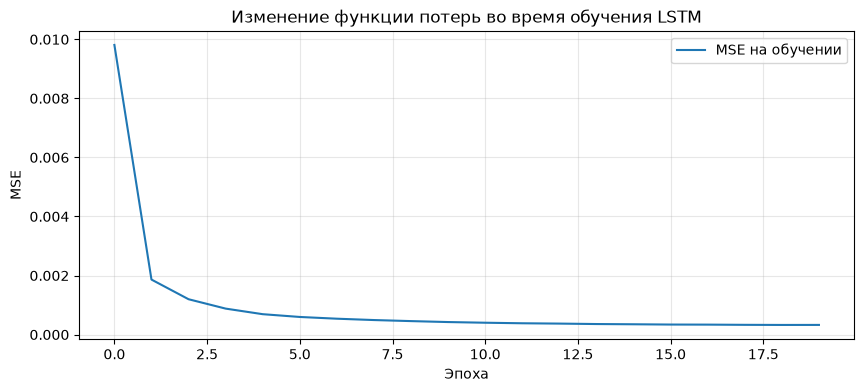

In [15]:
plt.figure(figsize=(10, 4))
plt.plot(history.history["loss"], label="MSE на обучении")
plt.title("Изменение функции потерь во время обучения LSTM")
plt.xlabel("Эпоха")
plt.ylabel("MSE")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 10. Получение прогноза на тестовой выборке

После обучения передаём тестовые окна модели и получаем прогнозы в масштабированном виде. Затем возвращаем значения к исходным единицам измерения с помощью обратного преобразования `inverse_transform`.

Важно: тестовые окна расположены в хронологическом порядке, поэтому прогнозы можно корректно сравнить с фактическими значениями тестового участка.

In [16]:
y_pred_scaled = model.predict(test_dataset, verbose=1)

# Получаем фактические значения тестового участка
y_test_scaled = test_targets

# Возвращаем исходный масштаб
y_pred = scaler.inverse_transform(y_pred_scaled)
y_test = scaler.inverse_transform(y_test_scaled)

print("Форма прогноза:", y_pred.shape)
print("Форма фактических значений:", y_test.shape)

94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step
Форма прогноза: (24000, 3)
Форма фактических значений: (24000, 3)


## 11. Оценка качества прогноза

Используем две метрики:

- **MAE (Mean Absolute Error)** — средняя абсолютная ошибка. Показывает, насколько в среднем прогноз отличается от фактического значения в единицах измерения параметра.
- **RMSE (Root Mean Squared Error)** — корень из средней квадратичной ошибки. Сильнее штрафует большие отклонения.

Чем меньше значения MAE и RMSE, тем точнее прогноз. Значения разных параметров могут иметь разные единицы измерения, поэтому метрики следует анализировать отдельно для каждого столбца.

Дополнительно будет построена матрица ошибок для категорий значений. Поскольку прогнозирование является задачей регрессии, для её построения непрерывные значения условно разделяются на три уровня: низкий, средний и высокий. Матрица используется как дополнительная визуальная оценка совпадения уровней, а не вместо MAE и RMSE.


In [17]:
metrics_rows = []

for i, col in enumerate(TARGET_COLUMNS):
    mae = mean_absolute_error(y_test[:, i], y_pred[:, i])
    rmse = np.sqrt(mean_squared_error(y_test[:, i], y_pred[:, i]))

    metrics_rows.append({
        "Параметр": col,
        "MAE": mae,
        "RMSE": rmse
    })

metrics_df = pd.DataFrame(metrics_rows)
display(metrics_df.round(6))

,Параметр,MAE,RMSE
0,U_SA,0.498596,0.876811
1,I_SA,0.060970,0.089533
2,P_SA,1.945510,2.794176


### 11.1. Матрица ошибок для прогнозируемых параметров

Для каждого параметра отдельно строится матрица ошибок. Границы категорий (низкий, средний и высокий уровень) рассчитываются по обучающей части данных, чтобы не использовать тестовые значения при определении порогов.

По горизонтали отображаются предсказанные категории, по вертикали — фактические. Диагональ матрицы показывает количество совпадений. Чем больше значений находится на диагонали, тем чаще модель правильно определяет уровень параметра.

Важно: это дополнительная оценка после дискретизации регрессионного прогноза. Основными метриками качества остаются MAE и RMSE.

Матрица ошибок: U_SA


,Прогноз: Низкий,Прогноз: Средний,Прогноз: Высокий
Факт: Низкий,12,7703,0
Факт: Средний,0,7498,5
Факт: Высокий,0,6056,2726


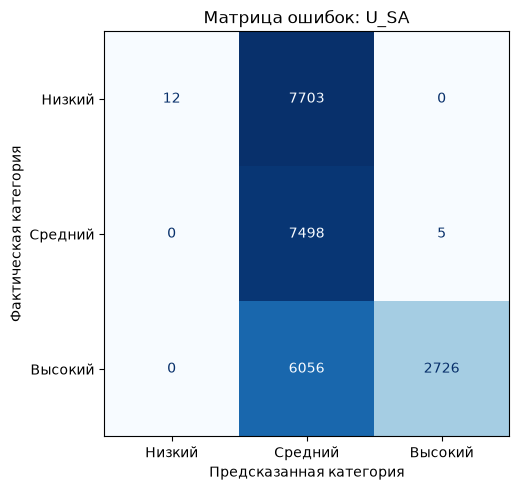

Матрица ошибок: I_SA


,Прогноз: Низкий,Прогноз: Средний,Прогноз: Высокий
Факт: Низкий,0,0,0
Факт: Средний,1003,15489,2
Факт: Высокий,2,2213,5291


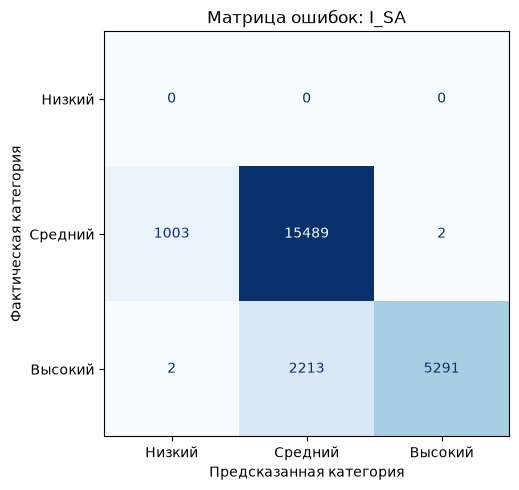

Матрица ошибок: P_SA


,Прогноз: Низкий,Прогноз: Средний,Прогноз: Высокий
Факт: Низкий,0,0,0
Факт: Средний,964,15569,18
Факт: Высокий,1,2323,5125


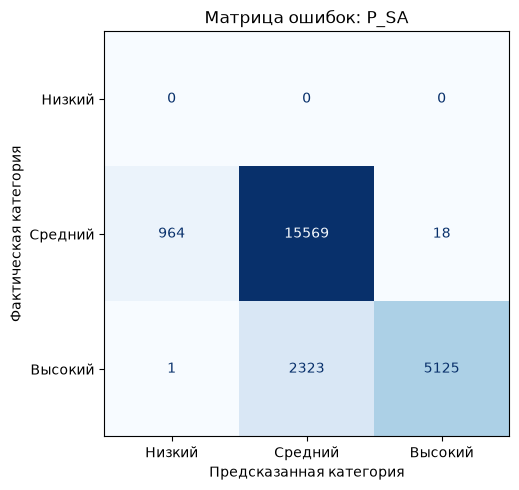

Матрицы ошибок сохранены в: results\confusion_matrices


In [18]:
# Категоризация непрерывных значений для построения матрицы ошибок.
# Пороги определяются только по обучающей части датасета.

CONFUSION_DIR = os.path.join("results", "confusion_matrices")
os.makedirs(CONFUSION_DIR, exist_ok=True)

for i, col in enumerate(TARGET_COLUMNS):
    train_values = values[:split_index, i]

    # Границы между низким, средним и высоким уровнями
    thresholds = np.quantile(train_values, [1/3, 2/3])
    thresholds = np.unique(thresholds)

    # Если значения почти не различаются, число категорий может быть меньше трёх
    y_true_category = np.digitize(y_test[:, i], thresholds)
    y_pred_category = np.digitize(y_pred[:, i], thresholds)

    number_of_categories = len(thresholds) + 1
    category_labels = (
        ["Низкий", "Средний", "Высокий"][:number_of_categories]
    )

    cm = confusion_matrix(
        y_true_category,
        y_pred_category,
        labels=np.arange(number_of_categories)
    )

    print(f"Матрица ошибок: {col}")
    display(pd.DataFrame(
        cm,
        index=[f"Факт: {label}" for label in category_labels],
        columns=[f"Прогноз: {label}" for label in category_labels]
    ))

    fig, ax = plt.subplots(figsize=(6, 5))
    display_obj = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=category_labels
    )
    display_obj.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )
    ax.set_title(f"Матрица ошибок: {col}")
    ax.set_xlabel("Предсказанная категория")
    ax.set_ylabel("Фактическая категория")
    plt.tight_layout()
    plt.show()

    # Сохраняем матрицу в CSV
    safe_col_name = re.sub(r"[^0-9A-Za-zА-Яа-я_-]+", "_", str(col))
    cm_df = pd.DataFrame(
        cm,
        index=[f"Факт: {label}" for label in category_labels],
        columns=[f"Прогноз: {label}" for label in category_labels]
    )
    cm_df.to_csv(
        os.path.join(CONFUSION_DIR, f"confusion_matrix_{safe_col_name}.csv"),
        encoding="utf-8-sig"
    )

print("Матрицы ошибок сохранены в:", CONFUSION_DIR)

## 12. Графики фактических и прогнозируемых значений

Для каждого параметра строим график на тестовом участке:
- фактические значения — измерения из CSV;
- прогноз — результат работы LSTM.

Чтобы графики оставались читаемыми, отображаем не более первых 1500 тестовых точек. Это ограничение влияет только на отображение, а метрики выше рассчитываются по всей тестовой выборке.

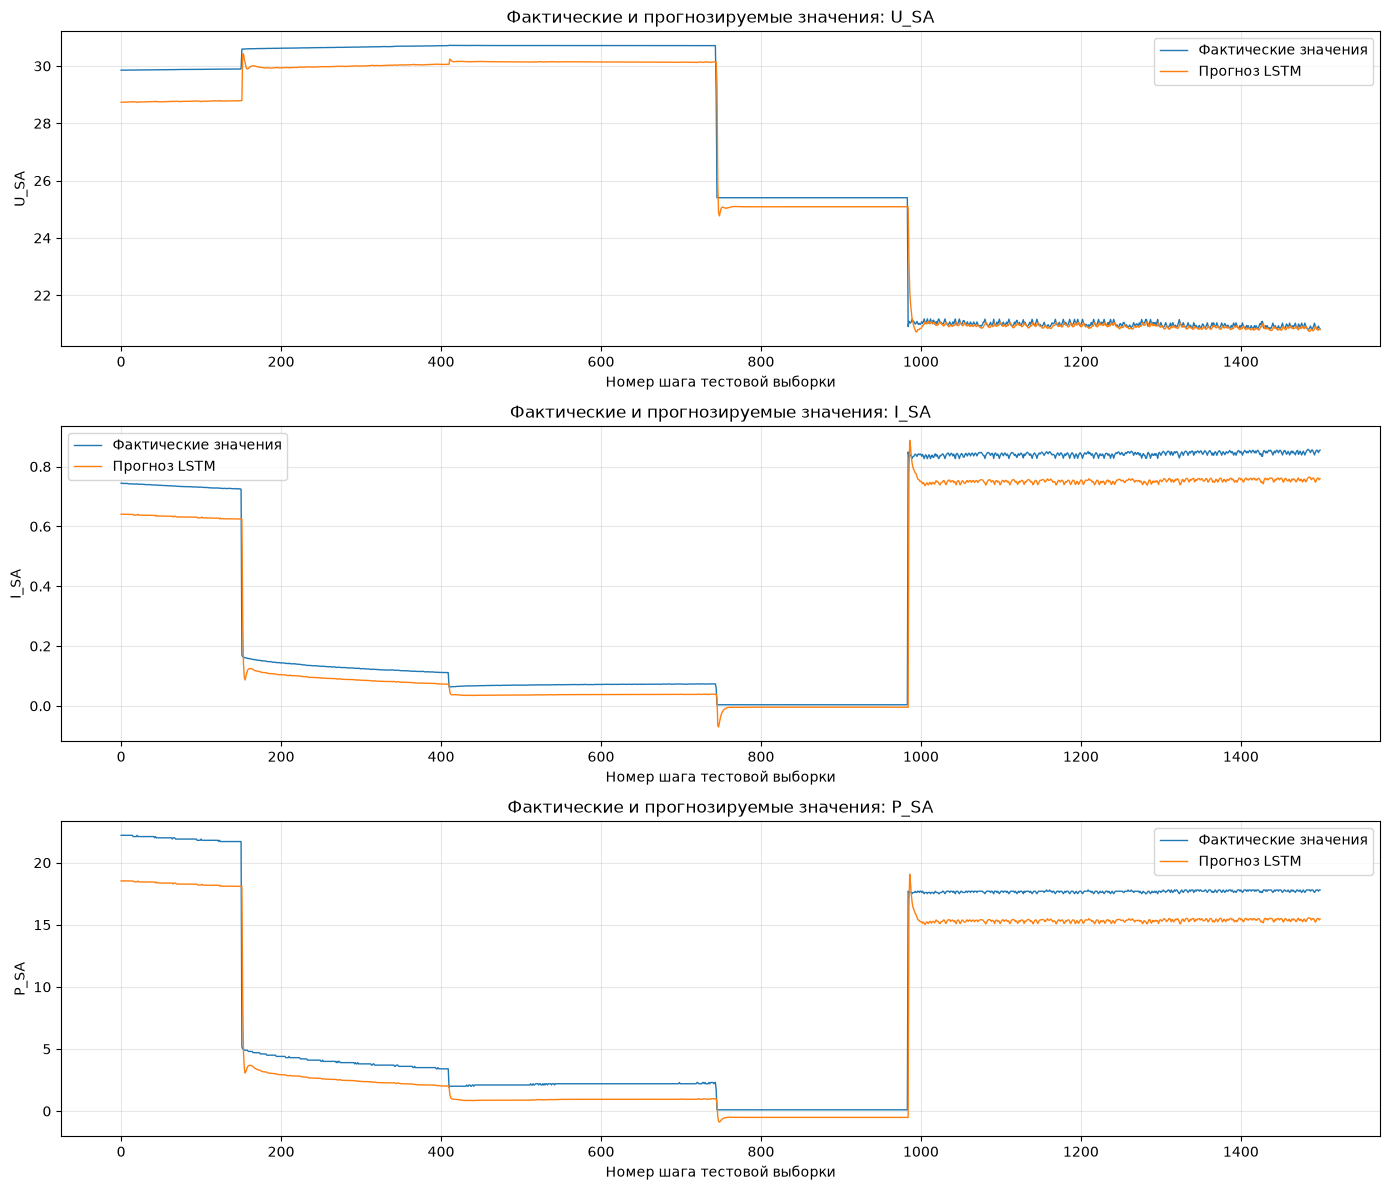

In [19]:
POINTS_TO_PLOT = min(1500, len(y_test))
x_axis = np.arange(POINTS_TO_PLOT)

fig, axes = plt.subplots(
    len(TARGET_COLUMNS), 1,
    figsize=(14, 4 * len(TARGET_COLUMNS)),
    squeeze=False
)

for i, col in enumerate(TARGET_COLUMNS):
    axes[i, 0].plot(
        x_axis,
        y_test[:POINTS_TO_PLOT, i],
        label="Фактические значения",
        linewidth=1
    )
    axes[i, 0].plot(
        x_axis,
        y_pred[:POINTS_TO_PLOT, i],
        label="Прогноз LSTM",
        linewidth=1
    )
    axes[i, 0].set_title(f"Фактические и прогнозируемые значения: {col}")
    axes[i, 0].set_xlabel("Номер шага тестовой выборки")
    axes[i, 0].set_ylabel(str(col))
    axes[i, 0].legend()
    axes[i, 0].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 12.1. График ошибки прогноза

Дополнительно строим график разности между фактическим значением и прогнозом. Положительная ошибка означает, что модель занизила прогноз, отрицательная — завысила.

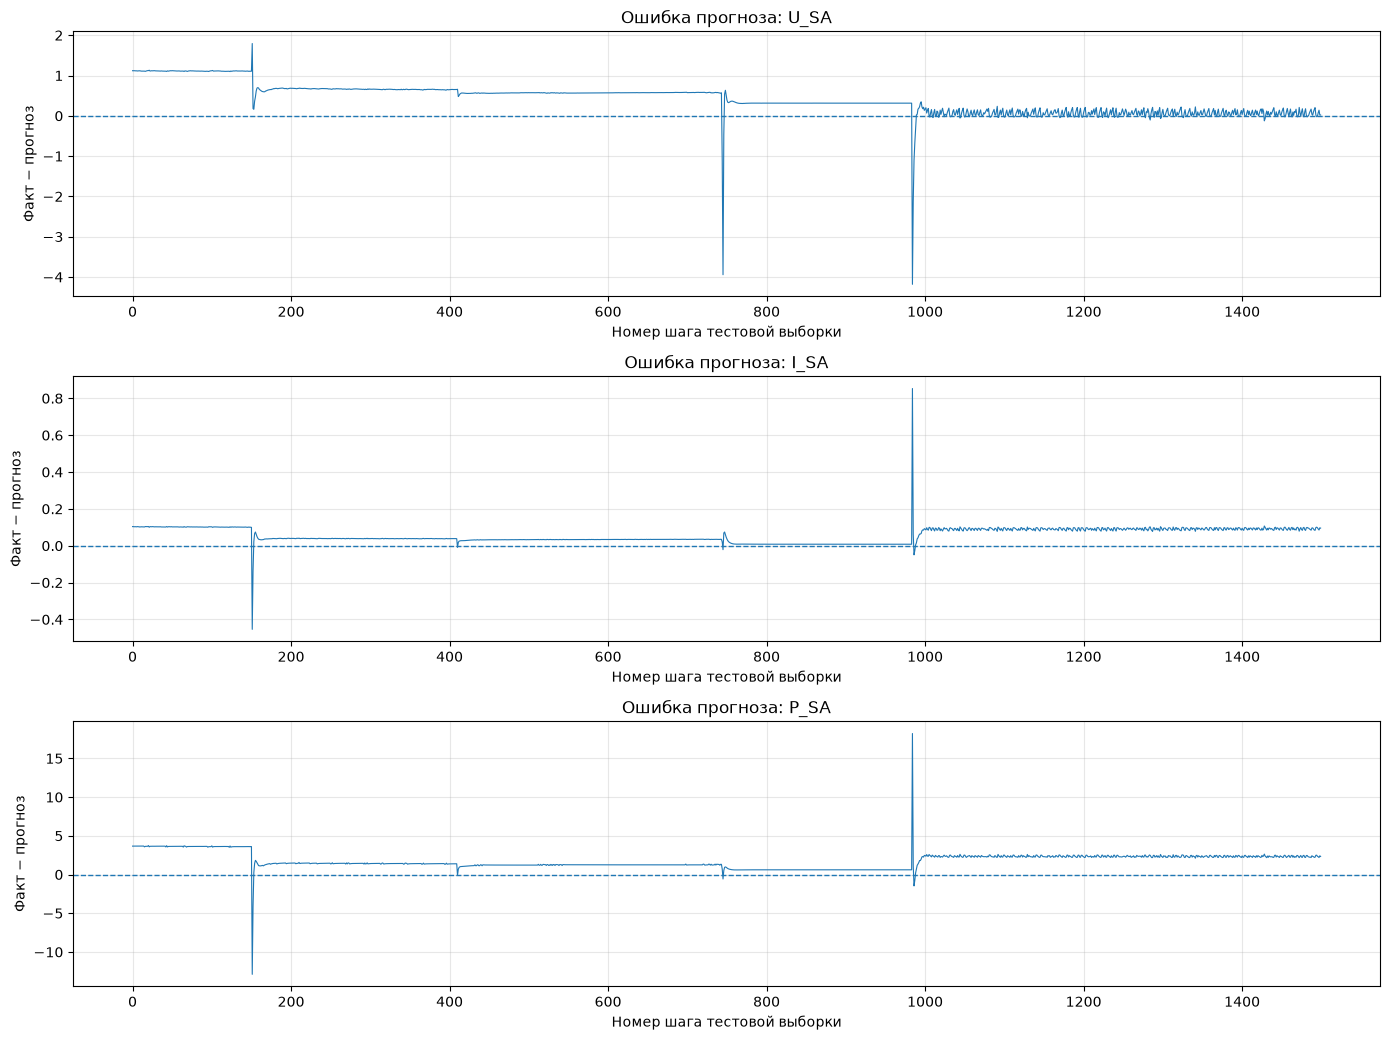

In [20]:
fig, axes = plt.subplots(
    len(TARGET_COLUMNS), 1,
    figsize=(14, 3.5 * len(TARGET_COLUMNS)),
    squeeze=False
)

for i, col in enumerate(TARGET_COLUMNS):
    errors = y_test[:POINTS_TO_PLOT, i] - y_pred[:POINTS_TO_PLOT, i]
    axes[i, 0].plot(x_axis, errors, linewidth=0.8)
    axes[i, 0].axhline(0, linestyle="--", linewidth=1)
    axes[i, 0].set_title(f"Ошибка прогноза: {col}")
    axes[i, 0].set_xlabel("Номер шага тестовой выборки")
    axes[i, 0].set_ylabel("Факт − прогноз")
    axes[i, 0].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 13. Прогноз следующего временного шага

Используем последние 60 наблюдений файла, чтобы получить прогноз на один шаг вперёд. Это демонстрационный прогноз за пределами имеющихся данных, поэтому фактическое значение для его проверки в CSV отсутствует.

In [21]:
last_window = all_scaled[-WINDOW_SIZE:]
last_window = last_window.reshape(1, WINDOW_SIZE, number_of_features)

next_scaled = model.predict(last_window, verbose=0)
next_value = scaler.inverse_transform(next_scaled)[0]

next_forecast = pd.DataFrame({
    "Параметр": TARGET_COLUMNS,
    "Прогноз следующего шага": next_value
})

display(next_forecast)

,Параметр,Прогноз следующего шага
0,U_SA,27.871506
1,I_SA,0.990924
2,P_SA,28.410957


## 14. Сохранение обученной модели и результатов

Сохраняем:
- обученную нейронную сеть в формате `.keras`;
- таблицу метрик в CSV;
- таблицу прогноза тестовой выборки в CSV;
- обработанный датасет в папке `data`;
- матрицы ошибок по каждому прогнозируемому параметру в папке `results/confusion_matrices`.

Файлы будут записаны в папку `results`, которая создаётся автоматически.

In [22]:
RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

model_path = os.path.join(RESULTS_DIR, "lstm_telemetry_model.keras")
metrics_path = os.path.join(RESULTS_DIR, "forecast_metrics.csv")
predictions_path = os.path.join(RESULTS_DIR, "test_predictions.csv")
processed_data_path = os.path.join("data", "processed_dataset.csv")

model.save(model_path)
metrics_df.to_csv(metrics_path, index=False, encoding="utf-8-sig")

predictions_df = pd.DataFrame()
for i, col in enumerate(TARGET_COLUMNS):
    predictions_df[f"{col}_actual"] = y_test[:, i]
    predictions_df[f"{col}_predicted"] = y_pred[:, i]

predictions_df.to_csv(predictions_path, index=False, encoding="utf-8-sig")

print("Сохранено:")
print(model_path)
print(metrics_path)
print(predictions_path)
print(processed_data_path)
print(os.path.join(RESULTS_DIR, "confusion_matrices"))

Сохранено:
results\lstm_telemetry_model.keras
results\forecast_metrics.csv
results\test_predictions.csv
data\processed_dataset.csv
results\confusion_matrices


## 15. Вывод по лабораторной работе

В ходе лабораторной работы были рассмотрены основные этапы прогнозирования телеметрических временных рядов с использованием рекуррентной нейронной сети LSTM.

Были выполнены загрузка и анализ датасета XJTU-SPS, выбор числовых параметров, обработка пропусков, масштабирование и разделение данных с сохранением временного порядка. На основе исторических наблюдений были сформированы оконные выборки: каждая последовательность содержит `WINDOW_SIZE` предыдущих измерений, а целевым значением является следующий временной шаг.

Затем была создана и обучена модель LSTM. Качество прогноза оценено с помощью MAE и RMSE, а результаты визуально сопоставлены с фактическими значениями тестовой выборки.

**Перед сдачей заполните вывод конкретными результатами из таблицы метрик:** укажите выбранные параметры, значения MAE и RMSE, а также кратко оцените, насколько прогноз повторяет динамику фактического ряда.

### Что важно указать в отчёте
1. Какие именно столбцы CSV использовались как прогнозируемые параметры.
2. Сколько строк было использовано после очистки.
3. Какой размер окна и доля обучающей выборки применялись.
4. Сколько эпох фактически обучалась модель.
5. Полученные значения MAE и RMSE.
6. По графикам — насколько хорошо модель воспроизводит тренд и локальные колебания.

### Ограничения эксперимента
- Автоматический выбор столбцов является предварительным: проверьте, что они действительно соответствуют нужным телеметрическим каналам.
- Если в CSV нет явных столбцов температуры, напряжения и тока, нельзя подписывать выбранные каналы этими названиями без подтверждения по документации датасета.
- В базовой реализации прогнозируется один следующий шаг, а не длинный горизонт на десятки или сотни секунд.
- Ограничение `MAX_ROWS` используется для экономии памяти и времени; при необходимости эксперимент можно повторить на большем объёме данных.